# MVP — Análise de Dados: A Bilheteria do Cinema no Brasil (2009–2017)

**Pós-graduação em Ciência de Dados e Analytics — PUC-RJ**
Sprint: Análise de Dados | MVP

**Aluno:** Daniel Siqueira
**Dataset:** Bilheteria de Obras por Semana — ANCINE (Dados Abertos)
**Repositório:** [github.com/danielsiqueiradev/MVP_Analise_De_Dados_PUC-RJ](https://github.com/danielsiqueiradev/MVP_Analise_De_Dados_PUC-RJ)

---

## 1. Definição do problema e dos dados

### 1.1 Problema e relevância

O Brasil figura entre os maiores mercados de cinema do mundo em número de espectadores, mas convive com um paradoxo recorrente no debate público e na política audiovisual: a maior parte da renda de bilheteria vem de filmes estrangeiros — sobretudo de Hollywood — enquanto a produção nacional disputa uma fatia pequena e instável do público. Medidas de fomento (cotas de tela, fundos, renúncia fiscal) são avaliadas continuamente, e qualquer discussão sobre o "espaço do cinema nacional" passa por quantificar o que de fato aconteceu nas bilheterias.

**Problema analisado:** caracterizar o mercado de bilheteria de cinema no Brasil entre 2009 e 2017 — sua evolução, concentração, sazonalidade e a participação efetiva das obras nacionais — a partir dos registros oficiais de exibição da ANCINE.

### 1.2 Unidade de observação

Cada linha do dataset representa **uma obra cinematográfica (filme) em uma semana de exibição** no circuito comercial brasileiro: o público total, a renda bruta, o número de salas e de cópias daquela obra naquela semana. A semana de exibição do mercado brasileiro vai de quinta a quarta-feira.

### 1.3 Perguntas investigáveis e hipóteses

| ID | Pergunta | Hipótese inicial |
|----|----------|------------------|
| **H1** | Como evoluiu o mercado exibidor (público, renda, preço médio e nº de obras) entre 2009 e 2017? | A renda cresceu proporcionalmente mais que o público, puxada pelo reajuste do preço do ingresso |
| **H2** | Qual a participação das obras nacionais no público e na renda? | Obras nacionais são parcela relevante do catálogo, mas capturam fatia menor e instável do público, dependente de poucos sucessos |
| **H3** | O mercado é concentrado? | Poucas obras e poucas distribuidoras respondem pela maior parte do público (concentração tipo Pareto) |
| **H4** | Quais gêneros e países de origem dominam a bilheteria? | Ficção e obras dos EUA dominam; documentário tem presença de catálogo sem presença de público |
| **H5** | Existe sazonalidade mensal na frequência aos cinemas? | Picos nos meses de férias escolares (janeiro/julho) |
| **H6** | Quanto tempo as obras permanecem em cartaz e qual a relação entre salas e público? | Vida útil típica curta; público cresce com salas, mas com rendimento decrescente por sala (saturação) |

### 1.4 Objetivo analítico

O objetivo deste MVP é **descritivo-diagnóstico**: produzir uma caracterização empírica do mercado e deixar os dados limpos, documentados e estruturados em dois níveis de análise (obra × semana e obra agregada).

Caso a base seja usada futuramente em uma etapa preditiva, o problema natural seria uma **regressão** com alvo `PUBLICO` (público total ou público da primeira semana de exibição), usando como atributos gênero, origem, distribuidora, salas de estreia, mês de estreia e tempo em cartaz — por exemplo, estimar o potencial de público de um lançamento. Essa etapa **não** faz parte do escopo deste trabalho, que termina na preparação dos dados.

### 1.5 Fonte dos dados

- **Origem:** ANCINE — Agência Nacional do Cinema, portal de Dados Abertos do Governo Federal / Observatório Brasileiro do Cinema e do Audiovisual (OCA): https://dados.gov.br e https://oca.ancine.gov.br
- **Arquivo:** `BilheteriaObrasSemana.csv`
- **Data de obtenção:** novembro de 2026
- **Período dos dados:** anos cinematográficos de 2009 a 2017 (semanas de exibição entre 02/01/2009 e 03/01/2018)
- **Recortes realizados:** nenhum — o arquivo é utilizado integralmente
- **Condições de uso:** dados públicos abertos, sem informações pessoais; a cópia do arquivo é disponibilizada no repositório deste trabalho (`data/`) e o notebook a lê pela URL pública *raw* do GitHub, garantindo reprodutibilidade

### 1.6 Dicionário de dados

| Variável | Tipo | Unidade | Significado |
|----------|------|---------|-------------|
| `TITULO_ORIGINAL` | texto | — | Título original da obra |
| `TITULO_BRASILEIRO` | texto | — | Título de lançamento no Brasil |
| `GENERO` | categórica | — | Categoria da obra: Ficção, Documentário, Animação, Vídeomusical, Não Classificada |
| `PAIS_ORIGEM` | texto | — | País(es) de origem; coproduções listam vários países separados por vírgula |
| `CPB_ROE` | código (ID) | — | **Identificador único da obra** no Registro de Obras ANCINE; prefixo `B` = registrada como brasileira, `E` = estrangeira |
| `COPIAS` | inteira | cópias | Número de cópias disponibilizadas |
| `SALAS` | inteira | salas | Número de salas exibindo a obra na semana |
| `DT_INICIO_EXIBICAO` | data | AAAA-MM-DD | Início da semana de exibição |
| `DT_FIM_EXIBICAO` | data | AAAA-MM-DD | Fim da semana de exibição |
| `PUBLICO` | inteira | espectadores | Ingressos vendidos da obra na semana |
| `RENDA` | decimal | R$ (nominal) | Renda bruta de bilheteria da obra na semana |
| `RAZAO_SOCIAL_DISTRIBUIDORA` | texto | — | Nome da distribuidora |
| `REGISTRO_DISTRIBUIDORA` | código (ID) | — | Registro ANCINE da distribuidora |
| `CNPJ_DISTRIBUIDORA` | código (ID) | — | CNPJ da distribuidora (identificador estável entre variações de razão social) |
| `ANO_CINEMATOGRAFICO` | data | ano | Ano cinematográfico oficial ANCINE ao qual a semana pertence |

**Observações sobre identificadores e ausências:**
- `CPB_ROE`, `REGISTRO_DISTRIBUIDORA` e `CNPJ_DISTRIBUIDORA` são **códigos identificadores**, não variáveis mensuráveis.
- O dataset **não utiliza código explícito de ausência** (como `-1`, `NA` ou `SEM INFORMAÇÃO`) nas variáveis centrais; verifica-se adiante a ocorrência de zeros com papel ambíguo (`PUBLICO=0`, `RENDA=0`, `COPIAS=0`).
- `ANO_CINEMATOGRAFICO` ≠ ano civil: a ANCINE organiza o ano em semanas de exibição; a última semana de um ano cinematográfico pode terminar nos primeiros dias do ano civil seguinte.

## 2. Ambiente e reprodutibilidade

In [1]:
%matplotlib inline
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["axes.titlesize"] = 13

pd.set_option("display.max_columns", 30)

SEED = 42
np.random.seed(SEED)  # nenhuma operacao aleatoria e usada neste trabalho; seed fixada por convencao

COR_NAC, COR_ESTR = "#2ca02c", "#1f77b4"  # verde = nacional, azul = estrangeira

print("Versoes:", {"pandas": pd.__version__, "numpy": np.__version__,
      "matplotlib": matplotlib.__version__, "seaborn": sns.__version__})

Versoes: {'pandas': '3.0.3', 'numpy': '2.4.6', 'matplotlib': '3.10.9', 'seaborn': '0.13.2'}


## 3. Coleta dos dados

O dataset é lido diretamente da **URL pública (raw) do repositório GitHub** deste trabalho — mecanismo exigido para reprodução pelo avaliador, sem dependência de arquivos locais nem de credenciais. O *fallback* para `data/` existe apenas para desenvolvimento offline e não é o caminho oficial.

In [2]:
DATA_URL = ("https://raw.githubusercontent.com/danielsiqueiradev/"
            "MVP_Analise_De_Dados_PUC-RJ/main/data/BilheteriaObrasSemana.csv")

try:
    df_raw = pd.read_csv(DATA_URL)
    origem_dados = f"repositorio GitHub (raw): {DATA_URL}"
except Exception:
    df_raw = pd.read_csv("data/BilheteriaObrasSemana.csv")
    origem_dados = "copia local em data/ (fallback para execucao offline)"

print(f"Origem: {origem_dados}")
print(f"{df_raw.shape[0]:,} registros x {df_raw.shape[1]} colunas")
df_raw.head()

Origem: copia local em data/ (fallback para execucao offline)
51,176 registros x 15 colunas


,TITULO_ORIGINAL,TITULO_BRASILEIRO,GENERO,PAIS_ORIGEM,CPB_ROE,COPIAS,SALAS,DT_INICIO_EXIBICAO,DT_FIM_EXIBICAO,PUBLICO,RENDA,RAZAO_SOCIAL_DISTRIBUIDORA,REGISTRO_DISTRIBUIDORA,CNPJ_DISTRIBUIDORA,ANO_CINEMATOGRAFICO
0,COLLEGE,COLEGIAIS EM APUROS,Ficção,Estados Unidos,E1600557700000,8,8,2009-01-02,2009-01-08,833,5325.00,ANTONIO FERNANDES FILMES LTDA,532,02.668.665/0001-01,2009-01-01
1,O ABORTO DOS OUTROS,O ABORTO DOS OUTROS,Documentário,Brasil,B0800890900000,1,1,2009-01-02,2009-01-08,40,196.00,ANTONIO FERNANDES FILMES LTDA,532,02.668.665/0001-01,2009-01-01
2,ONDE ANDARÁ DULCE VEIGA?,ONDE ANDARÁ DULCE VEIGA?,Ficção,"Brasil, Chile",B0700801600000,1,1,2009-01-02,2009-01-08,66,210.00,ANTONIO FERNANDES FILMES LTDA,532,02.668.665/0001-01,2009-01-01
3,QUAND J'ETAIS CHANTEUR,QUANDO ESTOU AMANDO,Ficção,França,E1600545500000,1,1,2009-01-02,2009-01-08,103,842.92,ANTONIO FERNANDES FILMES LTDA,532,02.668.665/0001-01,2009-01-01
4,REC,REC,Ficção,Espanha,E1600619700000,2,2,2009-01-02,2009-01-08,252,1575.00,ANTONIO FERNANDES FILMES LTDA,532,02.668.665/0001-01,2009-01-01


## 4. Análise exploratória

### 4.1 Dimensões, tipos e inspeção inicial

In [3]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 51176 entries, 0 to 51175
Data columns (total 15 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   TITULO_ORIGINAL             51176 non-null  str    
 1   TITULO_BRASILEIRO           51176 non-null  str    
 2   GENERO                      51176 non-null  str    
 3   PAIS_ORIGEM                 51176 non-null  str    
 4   CPB_ROE                     51176 non-null  str    
 5   COPIAS                      51176 non-null  int64  
 6   SALAS                       51176 non-null  int64  
 7   DT_INICIO_EXIBICAO          51176 non-null  str    
 8   DT_FIM_EXIBICAO             51176 non-null  str    
 9   PUBLICO                     51176 non-null  int64  
 10  RENDA                       51176 non-null  float64
 11  RAZAO_SOCIAL_DISTRIBUIDORA  51176 non-null  str    
 12  REGISTRO_DISTRIBUIDORA      51176 non-null  int64  
 13  CNPJ_DISTRIBUIDORA          51176 non-null

### 4.2 Estatísticas descritivas

Para as variáveis numéricas: mínimo, máximo, mediana, moda, média, desvio-padrão e número de ausências. Para as categóricas: frequências.

In [4]:
def estatisticas_numericas(frame, colunas):
    '''Resume variaveis numericas conforme exigido: min, max, mediana, moda,
    media, desvio-padrao e numero de ausencias.'''
    stats = frame[colunas].agg(["count", "mean", "std", "min", "median", "max"]).T
    stats["moda"] = [frame[c].mode().iloc[0] for c in colunas]
    stats["ausencias"] = frame[colunas].isna().sum()
    return stats[["count", "ausencias", "mean", "std", "min", "median", "moda", "max"]]

cols_num = ["COPIAS", "SALAS", "PUBLICO", "RENDA"]
estatisticas_numericas(df_raw, cols_num).round(2)

,count,ausencias,mean,std,min,median,moda,max
COPIAS,51176.0,0,20.72,78.01,0.0,1.0,0.0,1505.0
SALAS,51176.0,0,38.46,125.08,1.0,3.0,1.0,2073.0
PUBLICO,51176.0,0,26985.79,145637.01,0.0,323.0,40.0,4074628.0
RENDA,51176.0,0,325777.50,1880626.18,0.0,2733.5,120.0,61046213.0


**Leitura das estatísticas:** `PUBLICO` e `RENDA` têm médias muito acima das medianas (26.986 vs 323 espectadores; R$ 325 mil vs R$ 2,7 mil) e desvios-padrão maiores que as próprias médias — assimetria extrema à direita, típica de mercados de "hits". A moda de `SALAS` e `COPIAS` concentra-se nos valores mais baixos: a observação típica é uma obra em circuito pequeno. Não há ausências em nenhuma variável. **Limite:** com cauda tão longa, média e desvio são pouco representativos do "filme típico" — mediana e quantis informam melhor, ponto retomado nas distribuições da seção 4.4.

In [5]:
print("GENERO:")
print(df_raw["GENERO"].value_counts().to_string())
print("\nTipo de registro da obra (prefixo do CPB_ROE):")
print(df_raw["CPB_ROE"].str[0].map({"B": "Brasileira", "E": "Estrangeira"}).value_counts().to_string())
print("\nAno cinematografico:")
print(df_raw["ANO_CINEMATOGRAFICO"].value_counts().sort_index().to_string())
print("\nDistribuidoras distintas:", df_raw["CNPJ_DISTRIBUIDORA"].nunique(),
      "| Obras distintas (CPB_ROE):", df_raw["CPB_ROE"].nunique())

GENERO:
GENERO
Ficção              41655
Documentário         4849
Animação             4594
Vídeomusical           65
Não Classificada       13

Tipo de registro da obra (prefixo do CPB_ROE):
CPB_ROE
Estrangeira    38363
Brasileira     12813

Ano cinematografico:
ANO_CINEMATOGRAFICO
2009-01-01    6205
2010-01-01    5685
2011-01-01    5786
2012-01-01    5495
2013-01-01    5521
2014-01-01    5785
2015-01-01    5950
2016-01-01    5513
2017-01-01    5236

Distribuidoras distintas: 268 | Obras distintas (CPB_ROE): 3876


**Leitura das frequências:** ficção responde por ~81% dos registros semanais; documentário (~9%) e animação (~9%) dividem o restante. Os registros estão bem distribuídos entre os 9 anos cinematográficos (5,2–6,2 mil por ano). Há 3.876 obras e 268 CNPJs de distribuidoras. **Limite:** frequências no nível obra × semana favorecem obras longevas (uma obra com 20 semanas gera 20 registros); contagens por obra distinta aparecem na análise de concentração.

### 4.3 Ausências, duplicidades, inconsistências e valores extremos

In [6]:
print("Valores ausentes por coluna:")
print(df_raw.isna().sum().to_string())
print(f"\nRegistros duplicados (linha inteira): {df_raw.duplicated().sum()}")
# duplicidade funcional: mesma obra + mesma semana
dup_obra_semana = df_raw.duplicated(subset=["CPB_ROE", "DT_INICIO_EXIBICAO"]).sum()
print(f"Mesma obra na mesma semana (duplicidade funcional): {dup_obra_semana}")

Valores ausentes por coluna:
TITULO_ORIGINAL               0
TITULO_BRASILEIRO             0
GENERO                        0
PAIS_ORIGEM                   0
CPB_ROE                       0
COPIAS                        0
SALAS                         0
DT_INICIO_EXIBICAO            0
DT_FIM_EXIBICAO               0
PUBLICO                       0
RENDA                         0
RAZAO_SOCIAL_DISTRIBUIDORA    0
REGISTRO_DISTRIBUIDORA        0
CNPJ_DISTRIBUIDORA            0
ANO_CINEMATOGRAFICO           0

Registros duplicados (linha inteira): 0
Mesma obra na mesma semana (duplicidade funcional): 65


In [7]:
# Consistencia temporal
_dt_ini = pd.to_datetime(df_raw["DT_INICIO_EXIBICAO"])
_dt_fim = pd.to_datetime(df_raw["DT_FIM_EXIBICAO"])
dur = (_dt_fim - _dt_ini).dt.days

print(f"Periodo coberto: {_dt_ini.min().date()} a {_dt_fim.max().date()}")
print(f"Duracao das semanas (dias): {dur.value_counts().to_dict()}")
print("Meses de inicio das semanas 'curtas':", sorted(_dt_ini[dur < 6].dt.month.unique()))

ano_cine = pd.to_datetime(df_raw["ANO_CINEMATOGRAFICO"]).dt.year
print(f"Registros com ano civil != ano cinematografico: {(_dt_ini.dt.year != ano_cine).sum()}")

Periodo coberto: 2009-01-02 a 2018-01-03
Duracao das semanas (dias): {6: 51058, 5: 118}
Meses de inicio das semanas 'curtas': [np.int32(3)]
Registros com ano civil != ano cinematografico: 90


In [8]:
# Zeros e inconsistencias de preenchimento
print(f"PUBLICO = 0: {(df_raw['PUBLICO'] == 0).sum()} registros")
print(f"RENDA = 0:   {(df_raw['RENDA'] == 0).sum()} registros")
print(f"PUBLICO = 0 e RENDA = 0 simultaneos: {((df_raw['PUBLICO'] == 0) & (df_raw['RENDA'] == 0)).sum()}")
print(f"RENDA = 0 com PUBLICO > 0: {((df_raw['RENDA'] == 0) & (df_raw['PUBLICO'] > 0)).sum()}")
print(f"COPIAS = 0 com SALAS >= 1: {((df_raw['COPIAS'] == 0) & (df_raw['SALAS'] >= 1)).sum()} "
      f"({((df_raw['COPIAS'] == 0) & (df_raw['SALAS'] >= 1)).mean():.0%} do total)")
print(f"SALAS > COPIAS: {(df_raw['SALAS'] > df_raw['COPIAS']).sum()} registros")

PUBLICO = 0: 54 registros
RENDA = 0:   80 registros
PUBLICO = 0 e RENDA = 0 simultaneos: 54
RENDA = 0 com PUBLICO > 0: 26
COPIAS = 0 com SALAS >= 1: 19473 (38% do total)
SALAS > COPIAS: 25458 registros


In [9]:
# Valores extremos: erro de registro ou fato do fenomeno?
print("Top 5 maiores publicos semanais:")
top_pub = df_raw.nlargest(5, "PUBLICO")[["TITULO_BRASILEIRO", "DT_INICIO_EXIBICAO",
                                        "SALAS", "PUBLICO", "RENDA"]]
print(top_pub.to_string(index=False))
print("\nTicket medio implicito (RENDA/PUBLICO) dos maiores publicos: R$",
      (top_pub["RENDA"] / top_pub["PUBLICO"]).round(2).tolist())
print("\nTicket medio implicito fora de faixa plausivel (<R$1 ou >R$100):",
      ((df_raw["RENDA"] / df_raw["PUBLICO"].replace(0, np.nan)) < 1).sum(),
      "e",
      ((df_raw["RENDA"] / df_raw["PUBLICO"].replace(0, np.nan)) > 100).sum())

Top 5 maiores publicos semanais:
                     TITULO_BRASILEIRO DT_INICIO_EXIBICAO  SALAS  PUBLICO       RENDA
         CAPITÃO AMÉRICA: GUERRA CIVIL         2016-04-28   1635  4074628 61046213.00
A SAGA CREPÚSCULO: AMANHECER - PARTE 2         2012-11-16   1194  3624972 38738922.12
           THE AVENGERS: OS VINGADORES         2012-04-27   1042  3540885 42865248.00
                  VELOZES & FURIOSOS 7         2015-04-02   1046  3538924 51861669.22
             VINGADORES: ERA DE ULTRON         2015-04-23   1356  3504303 50493946.00

Ticket medio implicito (RENDA/PUBLICO) dos maiores publicos: R$ [14.98, 10.69, 12.11, 14.65, 14.41]

Ticket medio implicito fora de faixa plausivel (<R$1 ou >R$100): 67 e 7


**Diagnóstico — extremos vs. erros de registro:**

- **Extremos legítimos:** o maior público semanal (4,07 milhões, estreia de *Capitão América: Guerra Civil* em 1.635 salas, ticket médio implícito ~R$ 14,98) é um fato do fenômeno — blockbusters —, não erro. Os tickets médios implícitos ficam quase todos dentro de uma faixa plausível: só 74 dos ~51 mil registros caem fora de R$ 1–100, em casos pontuais como sessões-evento promocionais.
- **Inconsistências de cadastro (não são erros que impeçam o uso, mas exigem decisão):**
  - `COPIAS = 0` em **38%** dos registros que têm `SALAS ≥ 1`, e `SALAS > COPIAS` em ~50% — o campo não é confiável no recorte semanal → tratado na decisão **D2**;
  - `PUBLICO = 0` e `RENDA = 0` simultâneos em 54 registros — obra consta em cartaz sem movimento reportado → tratado na decisão **D3**;
  - 142 registros cujo `CPB_ROE` tem prefixo `E` (estrangeira) mas `PAIS_ORIGEM` contém "Brasil" — divergência entre classificação cadastral e país declarado → tratado na decisão **D1**;
  - 90 registros em que o ano civil da data difere do `ANO_CINEMATOGRAFICO` (semanas na virada do ano) e 118 semanas "curtas" de 5 dias, todas iniciadas em março — fechamento do ano cinematográfico; são características do calendário oficial, não erros.
- **Sem ausências e sem duplicidades** (nem de linha inteira nem de obra × semana).

### 4.4 Distribuições individuais

Seleção justificada: com 15 colunas, priorizam-se as variáveis que carregam as perguntas — `PUBLICO` e `RENDA` (o fenômeno medido), `GENERO` (H4) e semanas em cartaz por obra (H6).

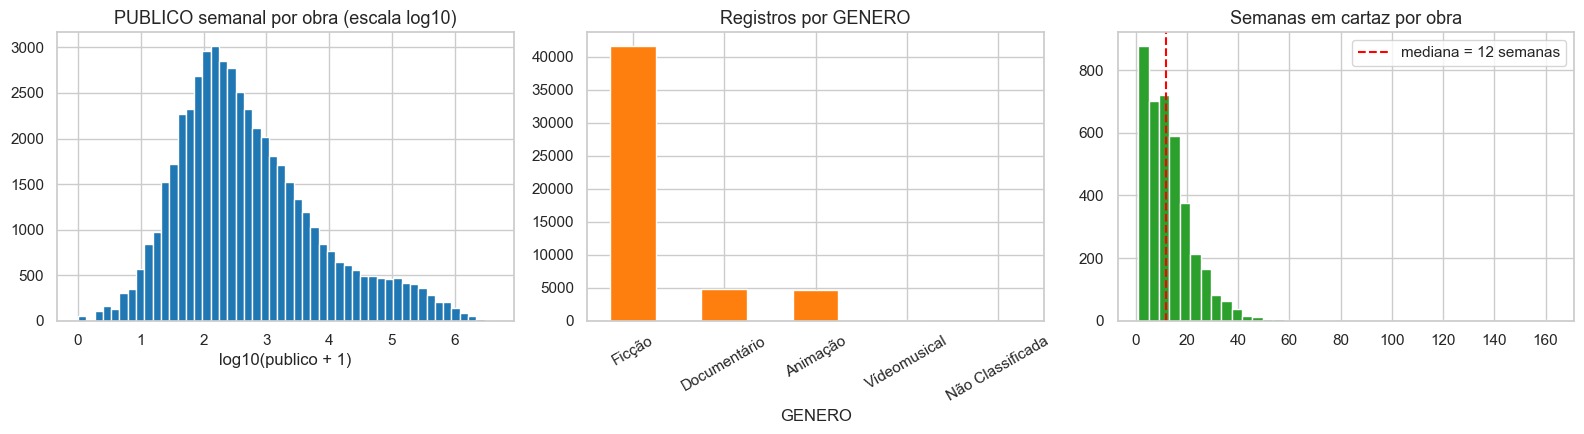

PUBLICO semanal: mediana 323 | media 26,986 | max 4,074,628 (max/mediana = 12,615x)
Semanas em cartaz: mediana 12 | media 13.2 | max 163


In [10]:
df_obras_aux = df_raw.groupby("CPB_ROE").size().rename("SEMANAS_CARTAZ")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

axes[0].hist(np.log10(df_raw["PUBLICO"] + 1), bins=50, color="#1f77b4")
axes[0].set_title("PUBLICO semanal por obra (escala log10)")
axes[0].set_xlabel("log10(publico + 1)")

df_raw["GENERO"].value_counts().plot.bar(ax=axes[1], color="#ff7f0e")
axes[1].set_title("Registros por GENERO")
axes[1].tick_params(axis="x", rotation=30)

axes[2].hist(df_obras_aux, bins=40, color="#2ca02c")
med = df_obras_aux.median()
axes[2].axvline(med, color="red", ls="--", label=f"mediana = {med:.0f} semanas")
axes[2].set_title("Semanas em cartaz por obra")
axes[2].legend()

plt.tight_layout()
plt.show()

print(f"PUBLICO semanal: mediana {df_raw['PUBLICO'].median():,.0f} | "
      f"media {df_raw['PUBLICO'].mean():,.0f} | max {df_raw['PUBLICO'].max():,.0f} "
      f"(max/mediana = {df_raw['PUBLICO'].max()/df_raw['PUBLICO'].median():,.0f}x)")
print(f"Semanas em cartaz: mediana {med:.0f} | media {df_obras_aux.mean():.1f} | max {df_obras_aux.max()}")

**Leitura:** a distribuição de `PUBLICO` é assimétrica mesmo em escala logarítmica — mediana de 323 ingressos/semana contra máximo de 4,07 milhões (razão ~12.600x). A permanência em cartaz tem mediana de 12 semanas e cauda até 163 (registro de *Relatos Selvagens*). Isso caracteriza o padrão "poucos hits, muita cauda" que H3 testa formalmente. **Limite:** a assimetria impõe escala logarítmica na maioria dos gráficos deste trabalho — eixos lineares esconderiam toda a informação relevante.

### 4.5 H1 — Evolução do mercado 2009–2017

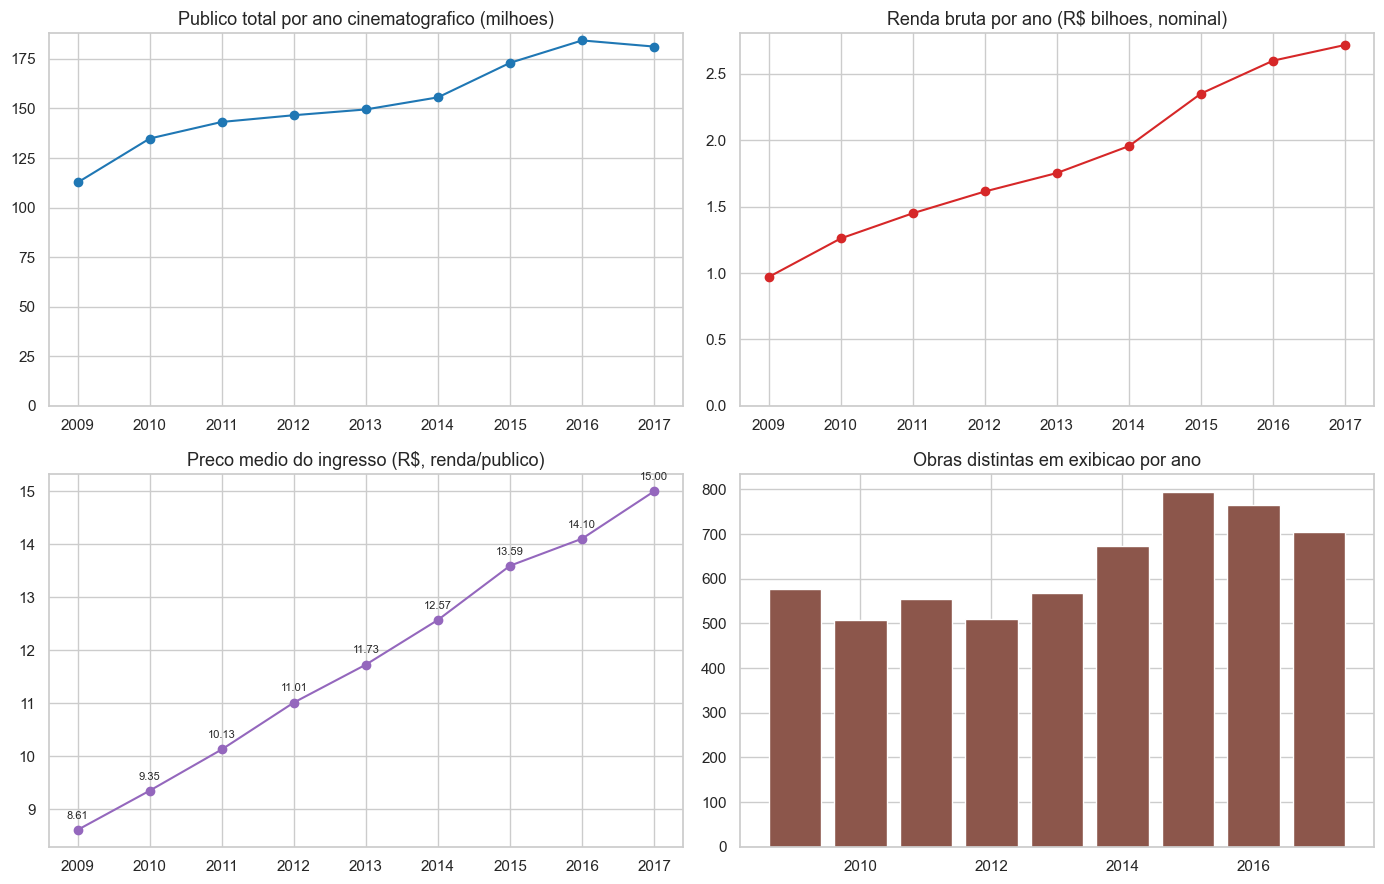

2009 -> 2017:  publico +61% | renda nominal +180% | ticket medio +74%


In [11]:
df_raw = df_raw.copy()
df_raw["ANO"] = pd.to_datetime(df_raw["ANO_CINEMATOGRAFICO"]).dt.year

anual = (df_raw.groupby("ANO")
               .agg(PUBLICO=("PUBLICO", "sum"), RENDA=("RENDA", "sum"),
                    OBRAS=("CPB_ROE", "nunique")))
anual["TICKET_MEDIO"] = anual["RENDA"] / anual["PUBLICO"]

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
axes[0, 0].plot(anual.index, anual["PUBLICO"] / 1e6, marker="o", color="#1f77b4")
axes[0, 0].set_title("Publico total por ano cinematografico (milhoes)")
axes[0, 0].set_ylim(0)
axes[0, 1].plot(anual.index, anual["RENDA"] / 1e9, marker="o", color="#d62728")
axes[0, 1].set_title("Renda bruta por ano (R$ bilhoes, nominal)")
axes[0, 1].set_ylim(0)
axes[1, 0].plot(anual.index, anual["TICKET_MEDIO"], marker="o", color="#9467bd")
axes[1, 0].set_title("Preco medio do ingresso (R$, renda/publico)")
for x, y in zip(anual.index, anual["TICKET_MEDIO"]):
    axes[1, 0].annotate(f"{y:.2f}", (x, y), textcoords="offset points",
                        xytext=(0, 8), ha="center", fontsize=8)
axes[1, 1].bar(anual.index, anual["OBRAS"], color="#8c564b")
axes[1, 1].set_title("Obras distintas em exibicao por ano")
plt.tight_layout()
plt.show()

cresc = lambda c: anual[c].loc[2017] / anual[c].loc[2009] - 1
print(f"2009 -> 2017:  publico {cresc('PUBLICO'):+.0%} | renda nominal {cresc('RENDA'):+.0%} | "
      f"ticket medio {cresc('TICKET_MEDIO'):+.0%}")

**Leitura (H1):** o público anual saiu de 112,7 milhões (2009) para 181,2 milhões (2017), **+61%**, com pico em 2016; a renda nominal saiu de R$ 0,97 bilhão para R$ 2,72 bilhões, **+180%**. O desempenho divergente é explicado pelo preço médio do ingresso: R$ 8,61 → R$ 15,00 (**+74%**). O catálogo também se ampliou (576 → 705 obras). **Limite:** `RENDA` é nominal — a série de renda superestima o crescimento real porque embute inflação; o "ticket médio" é uma razão agregada renda/público, não o preço efetivamente pago por sessão (mistura meia-entrada, 3D, salas premium).

### 4.6 H2 — Participação do cinema nacional

Classificação por `PAIS_ORIGEM` contendo "Brasil" (inclui coproduções com participação brasileira) — ver decisão **D1** na seção 5.

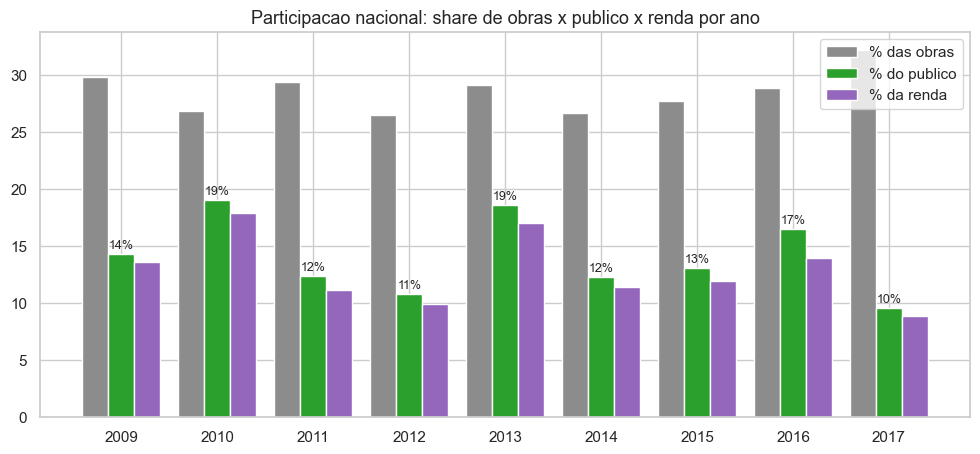

In [12]:
df_raw["NACIONAL"] = (df_raw["PAIS_ORIGEM"].str.split(",")
                      .apply(lambda ps: "Brasil" in [p.strip() for p in ps]))
df_raw["ORIGEM"] = np.where(df_raw["NACIONAL"], "Nacional", "Estrangeira")

nat = (df_raw.groupby(["ANO", "ORIGEM"])
             .agg(PUBLICO=("PUBLICO", "sum"), RENDA=("RENDA", "sum"),
                  OBRAS=("CPB_ROE", "nunique")).unstack())
share_pub = nat["PUBLICO"]["Nacional"] / nat["PUBLICO"].sum(axis=1) * 100
share_ren = nat["RENDA"]["Nacional"] / nat["RENDA"].sum(axis=1) * 100
share_obr = nat["OBRAS"]["Nacional"] / nat["OBRAS"].sum(axis=1) * 100

fig, ax = plt.subplots(figsize=(12, 5))
x = np.arange(len(share_pub.index)); w = 0.27
ax.bar(x - w, share_obr.values, w, label="% das obras", color="#8c8c8c")
ax.bar(x,     share_pub.values, w, label="% do publico", color=COR_NAC)
ax.bar(x + w, share_ren.values, w, label="% da renda", color="#9467bd")
for i, v in enumerate(share_pub.values):
    ax.annotate(f"{v:.0f}%", (i, v), textcoords="offset points", xytext=(0, 4),
                ha="center", fontsize=9)
ax.set_xticks(x, share_pub.index)
ax.set_title("Participacao nacional: share de obras x publico x renda por ano")
ax.legend()
plt.show()

In [13]:
df_obras_top = (df_raw.groupby(["CPB_ROE", "TITULO_BRASILEIRO", "NACIONAL"])
                      .agg(ANO=("ANO", "min"), PUBLICO=("PUBLICO", "sum"),
                           RENDA=("RENDA", "sum"),
                           SEMANAS=("DT_INICIO_EXIBICAO", "nunique"),
                           SALAS_MAX=("SALAS", "max")).reset_index())

print("Top 10 obras nacionais do periodo:")
top_nat = (df_obras_top[df_obras_top["NACIONAL"]]
           .nlargest(10, "PUBLICO")
           .assign(PUBLICO_MI=lambda t: (t["PUBLICO"] / 1e6).round(2),
                   RENDA_MI=lambda t: (t["RENDA"] / 1e6).round(1)))
top_nat[["TITULO_BRASILEIRO", "ANO", "PUBLICO_MI", "RENDA_MI",
         "SEMANAS", "SALAS_MAX"]].to_string(index=False)

Top 10 obras nacionais do periodo:


'           TITULO_BRASILEIRO  ANO  PUBLICO_MI  RENDA_MI  SEMANAS  SALAS_MAX\n          OS DEZ MANDAMENTOS 2016       11.31     116.8       37       1127\n            TROPA DE ELITE 2 2010       11.15     103.5       28        763\n      MINHA MÃE É UMA PEÇA 2 2016        9.23     124.7       18       1125\n          SE EU FOSSE VOCÊ 2 2009        5.79      47.6       44        315\n          DE PERNAS PRO AR 2 2012        4.85      50.3       15        718\n        MINHA MÃE É UMA PEÇA 2013        4.60      49.5       19        407\n                   NOSSO LAR 2010        4.06      36.1       15        444\nATÉ QUE A SORTE NOS SEPARE 2 2013        3.98      45.3       17        778\n            LOUCAS PRA CASAR 2015        3.73      45.7       20        604\n            DE PERNAS PRO AR 2010        3.51      31.0       28        346'

**Leitura (H2):** obras nacionais são **~29% do catálogo** exibido, mas seu share de público oscila entre **9,6% (2017) e 19,1% (2010)** — a de renda acompanha de perto. Os picos coincidem com megassucessos identificáveis: *Tropa de Elite 2* (11,1 milhões de espectadores, 2010), *Os Dez Mandamentos* (11,3 mi, 2016) e *Minha Mãe É uma Peça 2* (9,2 mi, 2016) — todos no top-10 geral do período. O ticket médio implícito das nacionais é menor que o das estrangeiras (~R$ 8,50 vs ~R$ 9,90 de média no período). **Limite:** o share anual é sensível a poucos títulos — um único fenômeno move vários pontos percentuais; e a classificação "nacional" inclui coproduções, superestimando levemente a fatia de filmes predominantemente brasileiros (ver D1).

### 4.7 H3 — Concentração de mercado

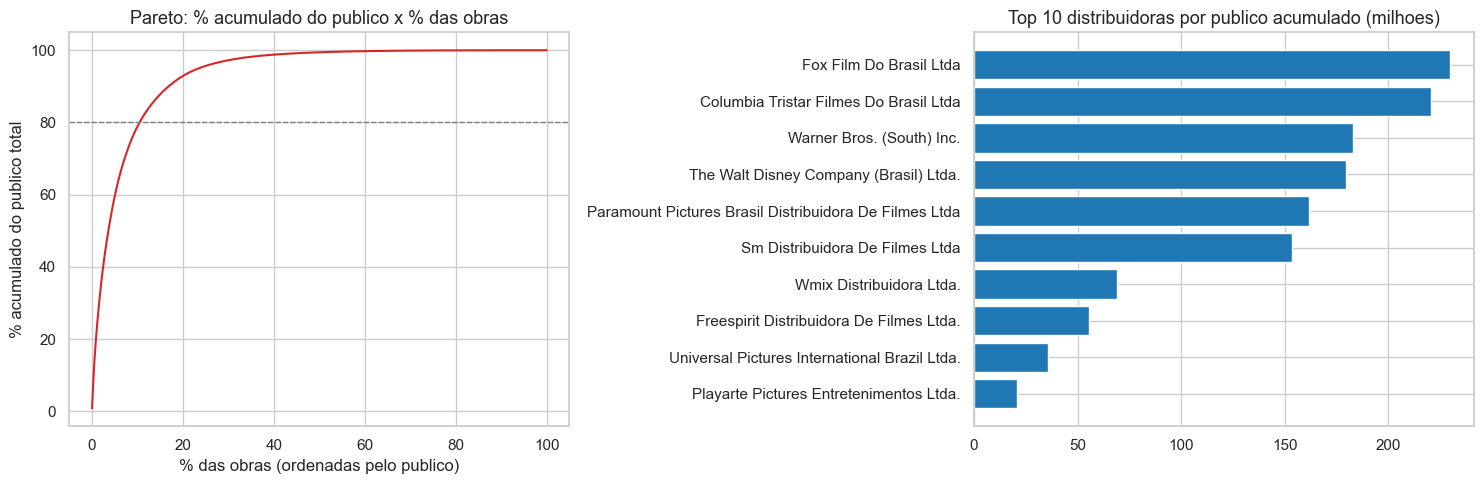

Top 10 obras: 7.3% do publico
80% do publico concentrado em 405 obras = 10% do catalogo
Top 5 distribuidoras: 70.6% do publico (268 CNPJs no total)
Mediana de publico por distribuidora: 2,510


In [14]:
obras = (df_raw.groupby("CPB_ROE")
               .agg(PUBLICO=("PUBLICO", "sum")).sort_values("PUBLICO", ascending=False))
cum = obras["PUBLICO"].cumsum() / obras["PUBLICO"].sum() * 100

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].plot(np.arange(1, len(cum) + 1) / len(cum) * 100, cum.values, color="#d62728")
axes[0].axhline(80, ls="--", color="gray", lw=1)
axes[0].set_title("Pareto: % acumulado do publico x % das obras")
axes[0].set_xlabel("% das obras (ordenadas pelo publico)")
axes[0].set_ylabel("% acumulado do publico total")

dist = (df_raw.groupby("CNPJ_DISTRIBUIDORA")
              .agg(DISTRIBUIDORA=("RAZAO_SOCIAL_DISTRIBUIDORA", "first"),
                   PUBLICO=("PUBLICO", "sum"), OBRAS=("CPB_ROE", "nunique"))
              .sort_values("PUBLICO", ascending=False))
top_dist = dist.head(10).iloc[::-1]
axes[1].barh(top_dist["DISTRIBUIDORA"].str.title(), top_dist["PUBLICO"] / 1e6,
             color="#1f77b4")
axes[1].set_title("Top 10 distribuidoras por publico acumulado (milhoes)")
plt.tight_layout()
plt.show()

n80 = (cum <= 80).sum()
print(f"Top 10 obras: {obras['PUBLICO'].head(10).sum() / obras['PUBLICO'].sum():.1%} do publico")
print(f"80% do publico concentrado em {n80} obras = {n80/len(obras):.0%} do catalogo")
print(f"Top 5 distribuidoras: {dist['PUBLICO'].head(5).sum() / dist['PUBLICO'].sum():.1%} "
      f"do publico ({len(dist)} CNPJs no total)")
print(f"Mediana de publico por distribuidora: {dist['PUBLICO'].median():,.0f}")

**Leitura (H3):** a curva de Pareto é mais inclinada que a regra 80/20: **10% do catálogo (405 de 3.876 obras) concentra 80% de todo o público** do período, e os 10 maiores sucessos sozinhos somam 7,3%. Nas distribuidoras, o top-5 — Fox, Columbia/Sony, Warner, Disney e Paramount, as majors de Hollywood da época — responde por **70,6%** do público entre 268 CNPJs cadastrados; a mediana por distribuidora é de apenas ~2,5 mil espectadores em 9 anos. Distribuidoras independentes nacionais (SM, WMIX, Freespirit, Playarte) aparecem no top-10 quando carregam os campeões nacionais. **Limite:** agregar por CNPJ consolida corretamente variações de razão social, mas não captura fusões/mudanças de CNPJ ao longo do tempo; e "concentração" mede participação de mercado, não poder de mercado — interpretar como causalidade exigiria outros dados.

### 4.8 H4 — Gêneros e países de origem

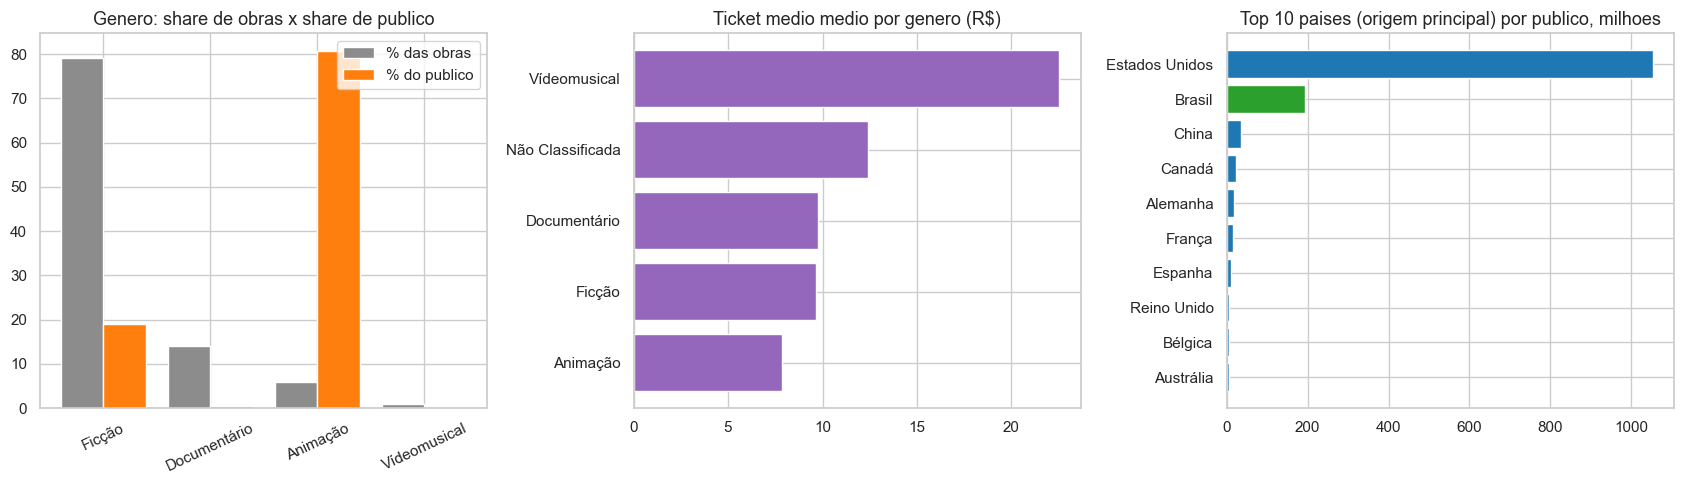

Share de publico por genero: {'Animação': np.float64(18.9), 'Documentário': np.float64(0.4), 'Ficção': np.float64(80.7), 'Vídeomusical': np.float64(0.0)}
Coproducoes no catalogo: 19% das obras


In [15]:
paises_limpos = df_raw["PAIS_ORIGEM"].str.split(",").apply(
    lambda ps: [p.strip() for p in ps])
df_raw["PAIS_PRINCIPAL"] = paises_limpos.str[0]
df_raw["COPRODUCAO"] = paises_limpos.str.len() > 1

df_obras_g = (df_raw.groupby("CPB_ROE")
                    .agg(GENERO=("GENERO", "first"), PAIS=("PAIS_PRINCIPAL", "first"),
                         COPROD=("COPRODUCAO", "first"), PUBLICO=("PUBLICO", "sum")))

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
g_obras = df_obras_g["GENERO"].value_counts()
g_pub = df_obras_g.groupby("GENERO")["PUBLICO"].sum() / 1e6
x = np.arange(len(g_obras)); w = 0.4
axes[0].bar(x - w/2, g_obras / g_obras.sum() * 100, w, label="% das obras", color="#8c8c8c")
axes[0].bar(x + w/2, g_pub / g_pub.sum() * 100, w, label="% do publico", color="#ff7f0e")
axes[0].set_xticks(x, g_obras.index, rotation=25)
axes[0].set_title("Genero: share de obras x share de publico")
axes[0].legend()

tkt_g = (df_raw[df_raw["PUBLICO"] > 0]
         .assign(TK=lambda t: t["RENDA"] / t["PUBLICO"])
         .groupby("GENERO")["TK"].mean().sort_values())
axes[1].barh(tkt_g.index, tkt_g.values, color="#9467bd")
axes[1].set_title("Ticket medio medio por genero (R$)")

top_pais = (df_obras_g.groupby("PAIS")["PUBLICO"].sum()
            .sort_values(ascending=False).head(10).iloc[::-1] / 1e6)
cores = [COR_NAC if p == "Brasil" else COR_ESTR for p in top_pais.index]
axes[2].barh(top_pais.index, top_pais.values, color=cores)
axes[2].set_title("Top 10 paises (origem principal) por publico, milhoes")
plt.tight_layout()
plt.show()

print(f"Share de publico por genero: {dict((g_pub / g_pub.sum() * 100).round(1))}")
print(f"Coproducoes no catalogo: {df_obras_g['COPROD'].mean():.0%} das obras")

**Leitura (H4):** ficção responde por ~79% das obras e ~81% do público — dominação esperada, mas com dois desvios instrutivos nos extremos: **documentário** soma 14% das obras para apenas **0,4% do público** (gênero de diversidade, não de bilheteria), e **animação** inverte a lógica com 6% do catálogo respondendo por ~19% do público — coerente com seu ticket médio mais alto (sessões família e 3D). Nos países, EUA lidera com folga (~1,05 bilhão de espectadores acumulados), Brasil é 2º (~192 milhões) e China/Canadá aparecem no pelotão por causa de superproduções de animação americanas registradas como coproduções com esses países na primeira posição. Coproduções são 19% do catálogo. **Limite:** `PAIS_PRINCIPAL` = primeiro país listado é uma simplificação — o público de uma coprodução é atribuído inteiro a um só país, o que distorce o ranking dos países não-majoritários.

### 4.9 H5 — Sazonalidade mensal

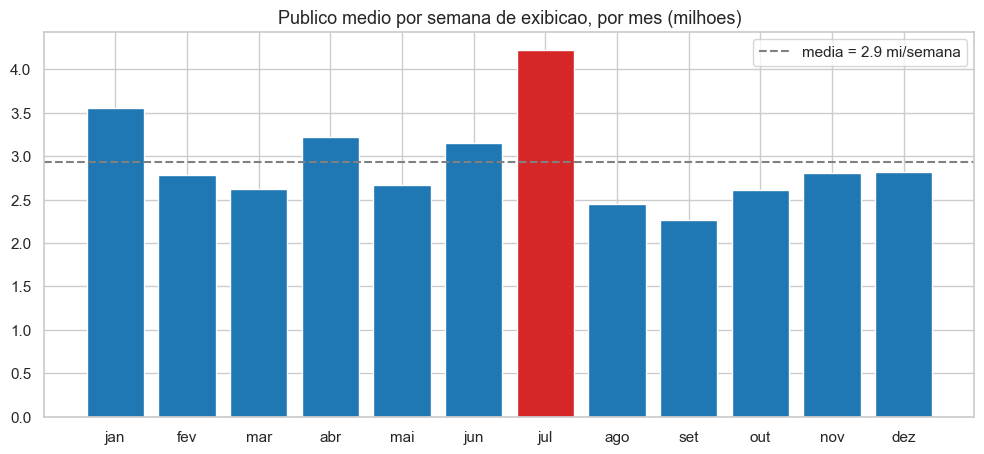

Melhor mes: jul (4.22 mi/sem) | pior: set (2.27 mi/sem) | razao 1.9x


In [16]:
df_raw["MES"] = pd.to_datetime(df_raw["DT_INICIO_EXIBICAO"]).dt.month
pub_mes = df_raw.groupby("MES")["PUBLICO"].sum()
sem_uniq = df_raw.groupby("MES")["DT_INICIO_EXIBICAO"].nunique()
pub_sem = pub_mes / sem_uniq  # publico medio por semana exibida no mes

nomes = ["jan","fev","mar","abr","mai","jun","jul","ago","set","out","nov","dez"]
fig, ax = plt.subplots(figsize=(12, 5))
cores = ["#d62728" if v == pub_sem.max() else "#1f77b4" for v in pub_sem.values]
ax.bar([nomes[m - 1] for m in pub_sem.index], pub_sem.values / 1e6, color=cores)
ax.axhline(pub_sem.mean() / 1e6, ls="--", color="gray",
           label=f"media = {pub_sem.mean()/1e6:.1f} mi/semana")
ax.set_title("Publico medio por semana de exibicao, por mes (milhoes)")
ax.legend()
plt.show()

print(f"Melhor mes: {nomes[pub_sem.idxmax()-1]} ({pub_sem.max()/1e6:.2f} mi/sem) | "
      f"pior: {nomes[pub_sem.idxmin()-1]} ({pub_sem.min()/1e6:.2f} mi/sem) | "
      f"razao {pub_sem.max()/pub_sem.min():.1f}x")

**Leitura (H5):** há sazonalidade clara alinhada ao calendário escolar: **julho** é o melhor mês (4,22 milhões/semana, contra média de 3,0), seguido de **janeiro** (3,56); os vales estão em **setembro, agosto e outubro** (2,3–2,6), meses sem férias escolares. A amplitude melhor/pior mês é de **1,9x** no público semanal médio. **Limite:** o indicador usa o mês de início da semana de exibição e mistura 9 anos — efeitos pontuais (feriados móveis, megassucessos concentrados em um mês específico) podem inflar ou esvaziar um mês em anos isolados; não há decomposição tendência × sazonalidade × ruído.

### 4.10 H6 — Tempo em cartaz e relação salas × público

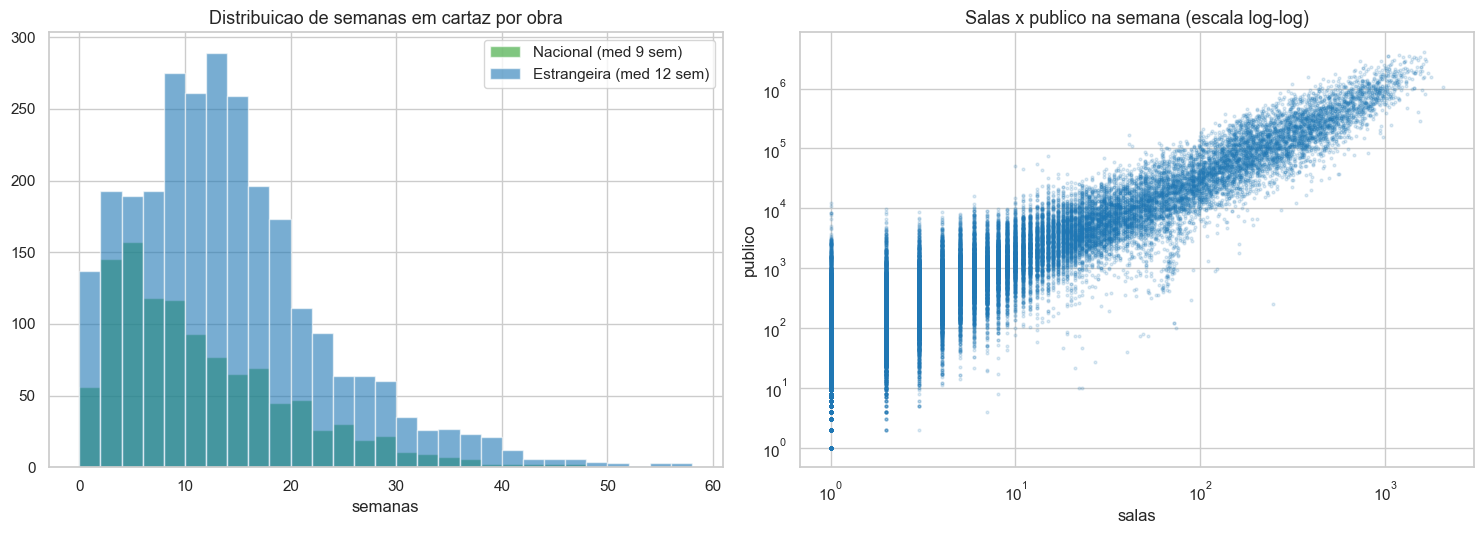

Publico semanal mediano POR SALA, por faixa de capilaridade:
faixa
1-10          83.0
11-50        181.0
51-200       305.0
201-500      530.0
501-1000     792.0
1000+       1229.0

Obras fora de cartaz em ate 4 semanas: 18%
Obras em cartaz por mais de 26 semanas: 9%


In [17]:
df_obras_sem = (df_raw.groupby(["CPB_ROE", "NACIONAL"])
                      .agg(SEMANAS=("DT_INICIO_EXIBICAO", "nunique")).reset_index())

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
bins = np.arange(0, 60, 2)
for origem, cor, nac in [("Nacional", COR_NAC, True), ("Estrangeira", COR_ESTR, False)]:
    s = df_obras_sem.loc[df_obras_sem["NACIONAL"] == nac, "SEMANAS"]
    axes[0].hist(s, bins=bins, alpha=0.6, label=f"{origem} (med {s.median():.0f} sem)", color=cor)
axes[0].set_title("Distribuicao de semanas em cartaz por obra")
axes[0].set_xlabel("semanas")
axes[0].legend()

mov = df_raw[df_raw["PUBLICO"] > 0]
axes[1].scatter(mov["SALAS"], mov["PUBLICO"], s=4, alpha=0.15, color="#1f77b4")
axes[1].set_xscale("log"); axes[1].set_yscale("log")
axes[1].set_title("Salas x publico na semana (escala log-log)")
axes[1].set_xlabel("salas"); axes[1].set_ylabel("publico")
plt.tight_layout()
plt.show()

faixas = pd.cut(mov["SALAS"], [0, 10, 50, 200, 500, 1000, 2100],
                labels=["1-10", "11-50", "51-200", "201-500", "501-1000", "1000+"])
pps = mov.assign(faixa=faixas).groupby("faixa", observed=True).apply(
    lambda g: (g["PUBLICO"] / g["SALAS"]).median(), include_groups=False)
print("Publico semanal mediano POR SALA, por faixa de capilaridade:")
print(pps.round(0).to_string())
print(f"\nObras fora de cartaz em ate 4 semanas: {(df_obras_sem['SEMANAS'] <= 4).mean():.0%}")
print(f"Obras em cartaz por mais de 26 semanas: {(df_obras_sem['SEMANAS'] > 26).mean():.0%}")

**Leitura (H6):** a permanência em cartaz é curta: **18%** das obras saem em até 4 semanas e só **9%** ultrapassam 26 semanas; a obra nacional tem mediana de **9 semanas**, contra **12** da estrangeira. Quanto à relação salas × público, os dados **refutam a saturação**: o público mediano **por sala sobe** com a capilaridade — ~83 espectadores/sala/semana para obras em 1–10 salas contra ~1.229 nas de 1.000+ salas. Lançamento amplo não dilui ocupação: blockbuster tem mais salas *e* mais público por sala. **Limite:** correlação não implica causalidade — distribuidoras abrem mais salas para filmes de maior apelo esperado (a capilaridade é resposta à demanda antecipada, não causa); e a mediana por faixa não captura a semana de estreia, quando o efeito seria mais forte.

## 5. Pré-processamento e decisões

### 5.1 Transformações aplicadas

A partir de `df_raw` (intocado), constrói-se `df` — mesma granularidade, com tipos corrigidos e variáveis derivadas — e `df_obras` — agregação por obra para as análises de H2–H6.

In [18]:
# --- df: nivel obra x semana, tipos corrigidos + derivadas ---
df = df_raw.copy()
df["DT_INICIO"] = pd.to_datetime(df["DT_INICIO_EXIBICAO"])
df["DT_FIM"] = pd.to_datetime(df["DT_FIM_EXIBICAO"])
df["ANO"] = pd.to_datetime(df["ANO_CINEMATOGRAFICO"]).dt.year
df["MES"] = df["DT_INICIO"].dt.month
df["PAIS_PRINCIPAL"] = df["PAIS_ORIGEM"].str.split(",").str[0].str.strip()
df["N_PAISES"] = df["PAIS_ORIGEM"].str.split(",").str.len()
df["COPRODUCAO"] = df["N_PAISES"] > 1
df["NACIONAL"] = df["PAIS_ORIGEM"].str.split(",").apply(
    lambda ps: "Brasil" in [p.strip() for p in ps])
df["ORIGEM"] = np.where(df["NACIONAL"], "Nacional", "Estrangeira")
df["TICKET_MEDIO"] = np.where(df["PUBLICO"] > 0, df["RENDA"] / df["PUBLICO"], np.nan)

# --- df_obras: nivel obra (uma linha por filme; chave CPB_ROE) ---
df_obras = (df.groupby("CPB_ROE")
              .agg(TITULO=("TITULO_BRASILEIRO", "first"), GENERO=("GENERO", "first"),
                   PAIS_PRINCIPAL=("PAIS_PRINCIPAL", "first"), NACIONAL=("NACIONAL", "first"),
                   ANO=("ANO", "min"), CNPJ_DISTRIBUIDORA=("CNPJ_DISTRIBUIDORA", "first"),
                   DISTRIBUIDORA=("RAZAO_SOCIAL_DISTRIBUIDORA", "first"),
                   SEMANAS_CARTAZ=("DT_INICIO", "nunique"), SALAS_MAX=("SALAS", "max"),
                   PUBLICO=("PUBLICO", "sum"), RENDA=("RENDA", "sum")).reset_index())
df_obras["TICKET_MEDIO"] = df_obras["RENDA"] / df_obras["PUBLICO"]
df_obras["ORIGEM"] = np.where(df_obras["NACIONAL"], "Nacional", "Estrangeira")

In [19]:
# Verificacao antes x depois
print("Integridade da transformacao:")
print(f"  df_raw: {df_raw.shape[0]:,} x {df_raw.shape[1]} | df: {df.shape[0]:,} x {df.shape[1]}")
print(f"  Linhas preservadas: {len(df) == len(df_raw)} | "
      f"CPBs preservados: {df['CPB_ROE'].nunique() == df_raw['CPB_ROE'].nunique()}")
print(f"  PUBLICO total: raw {df_raw['PUBLICO'].sum():,} = df {df['PUBLICO'].sum():,} = "
      f"obras {df_obras['PUBLICO'].sum():,}")
print(f"  RENDA total:   raw {df_raw['RENDA'].sum():,.0f} = df {df['RENDA'].sum():,.0f} = "
      f"obras {df_obras['RENDA'].sum():,.0f}")
print(f"  Ausencias criadas: {df.isna().sum().sum() - df_raw.isna().sum().sum():.0f} "
      f"(esperado: {df['PUBLICO'].eq(0).sum()}, de TICKET_MEDIO em semanas sem publico)")
print(f"  df_obras: {len(df_obras)} obras = {df['CPB_ROE'].nunique()} CPBs unicos")
df.dtypes.to_frame("dtype").T

Integridade da transformacao:
  df_raw: 51,176 x 21 | df: 51,176 x 25
  Linhas preservadas: True | CPBs preservados: True
  PUBLICO total: raw 1,381,024,924 = df 1,381,024,924 = obras 1,381,024,924
  RENDA total:   raw 16,671,989,431 = df 16,671,989,431 = obras 16,671,989,431
  Ausencias criadas: 54 (esperado: 54, de TICKET_MEDIO em semanas sem publico)
  df_obras: 3876 obras = 3876 CPBs unicos


,TITULO_ORIGINAL,TITULO_BRASILEIRO,GENERO,PAIS_ORIGEM,CPB_ROE,COPIAS,SALAS,DT_INICIO_EXIBICAO,DT_FIM_EXIBICAO,PUBLICO,RENDA,RAZAO_SOCIAL_DISTRIBUIDORA,REGISTRO_DISTRIBUIDORA,CNPJ_DISTRIBUIDORA,ANO_CINEMATOGRAFICO,ANO,NACIONAL,ORIGEM,PAIS_PRINCIPAL,COPRODUCAO,MES,DT_INICIO,DT_FIM,N_PAISES,TICKET_MEDIO
dtype,str,str,str,str,str,int64,int64,str,str,int64,float64,str,int64,str,str,int32,bool,str,object,bool,int32,datetime64[us],datetime64[us],int64,float64


**Verificação:** nenhuma linha ou obra foi perdida; os totais de `PUBLICO` e `RENDA` batem exatamente entre as três versões (raw → obra × semana → obra). As únicas ausências criadas são intencionais: `TICKET_MEDIO` é indefinido onde `PUBLICO = 0` (54 registros). Datas saem de texto para `datetime`; as demais colunas permanecem inalteradas.

### 5.2 Decisões relevantes

#### D1 — Como classificar uma obra como "nacional"?

- **Problema observado:** a classificação cadastral (prefixo `B`/`E` do `CPB_ROE`) diverge do `PAIS_ORIGEM` declarado em **142 registros** (prefixo `E` com "Brasil" na lista de países) — evidência na célula de inconsistências (seção 4.3) e na tabulação cruzada abaixo.
- **Alternativas:** (a) usar o prefixo do registro; (b) usar `PAIS_ORIGEM` contém "Brasil" (inclui coproduções); (c) usar apenas obras exclusivamente brasileiras.
- **Escolha:** **(b)**, porque `PAIS_ORIGEM` é o atributo descritivo do fenômeno medido e captura coproduções com participação brasileira; o prefixo reflete a formalidade do registro, não necessariamente a origem efetiva.
- **Comparação efetiva e verificação:** quantificada abaixo — as regras (a) e (b) divergem em menos de 0,3% dos registros e a diferença no share de público nacional é desprezível, então a escolha não altera as conclusões.
- **Limitação:** incluir coproduções superestima levemente a participação de obras predominantemente brasileiras; a alternativa (c) subestimaria ignorando a coprodução como forma de produção nacional.

In [20]:
# D1 - comparacao efetiva das alternativas de classificacao
regra_prefixo = df["CPB_ROE"].str[0] == "B"
regra_pais = df["NACIONAL"]
regra_estrita = (df["PAIS_ORIGEM"].str.strip() == "Brasil")

comp = pd.DataFrame({
    "regra": ["(a) prefixo CPB=B", "(b) contem Brasil", "(c) exclusivamente Brasil"],
    "registros": [regra_prefixo.sum(), regra_pais.sum(), regra_estrita.sum()],
    "share_publico_%": [df.loc[regra_prefixo, "PUBLICO"].sum() / df["PUBLICO"].sum() * 100,
                        df.loc[regra_pais, "PUBLICO"].sum() / df["PUBLICO"].sum() * 100,
                        df.loc[regra_estrita, "PUBLICO"].sum() / df["PUBLICO"].sum() * 100]})
comp["share_publico_%"] = comp["share_publico_%"].round(2)
print(comp.to_string(index=False))
print(f"\nRegistros divergentes entre (a) e (b): {(regra_prefixo != regra_pais).sum()} "
      f"({(regra_prefixo != regra_pais).mean():.2%})")

                    regra  registros  share_publico_%
        (a) prefixo CPB=B      12813            13.92
        (b) contem Brasil      12955            13.95
(c) exclusivamente Brasil      11331            13.66

Registros divergentes entre (a) e (b): 142 (0.28%)


#### D2 — Medida de capilaridade: `SALAS` ou `COPIAS`?

- **Problema observado:** `COPIAS = 0` em 38% dos registros com `SALAS ≥ 1`, e `SALAS > COPIAS` em ~50% — impossível se `COPIAS` medisse cópias em circulação naquela semana (seção 4.3).
- **Alternativas:** (a) usar `COPIAS`; (b) usar `SALAS`; (c) usar `SALAS` e manter `COPIAS` apenas como indicador de lançamento.
- **Escolha:** **(b)** — `SALAS` mede diretamente a capilaridade semanal da exibição e tem zeros apenas onde faz sentido conceitualmente nenhum; `COPIAS` parece registrar o volume de lançamento e não é atualizado semana a semana.
- **Comparação e verificação:** `SALAS` não tem zeros espúrios (mínimo 1) e apresenta correlação coerente com `PUBLICO`; `COPIAS` zeraria artificialmente 38% das observações. `COPIAS` é mantida no dataset mas fora das análises de capilaridade.
- **Limitação:** sem documentação oficial do campo, a interpretação de `COPIAS` permanece incerta — decisão conservadora é não inferir nada a partir dele.

In [21]:
# D2 - verificacao
print(f"SALAS: min={df['SALAS'].min()}, zeros={(df['SALAS'] == 0).sum()}, "
      f"mediana={df['SALAS'].median():.0f}")
print(f"COPIAS: min={df['COPIAS'].min()}, zeros={(df['COPIAS'] == 0).sum()} "
      f"({(df['COPIAS'] == 0).mean():.0%}), mediana={df['COPIAS'].median():.0f}")
print(f"Correlacao com PUBLICO (spearman): SALAS "
      f"{df[['SALAS', 'PUBLICO']].corr(method='spearman').iloc[0, 1]:.2f} | COPIAS "
      f"{df[['COPIAS', 'PUBLICO']].corr(method='spearman').iloc[0, 1]:.2f}")

SALAS: min=1, zeros=0, mediana=3
COPIAS: min=0, zeros=19473 (38%), mediana=1
Correlacao com PUBLICO (spearman): SALAS 0.88 | COPIAS 0.44


#### D3 — Registros com `PUBLICO = 0` e `RENDA = 0`: remover ou manter?

- **Problema observado:** 54 registros (0,1%) de obras em cartaz sem público nem renda reportados na semana.
- **Alternativas:** (a) remover como suspeita de erro; (b) manter; (c) imputar.
- **Escolha:** **(b) manter** — são plausíveis (obra residual em cartaz sem movimento, ou reporte incompleto da exibidora), sua remoção não altera nenhum agregado (somam 0 nos totais) e não há evidência de erro (são válidos sob qualquer regra de consistência).
- **Verificação:** manter ou remover não muda totais; a decisão afeta apenas `TICKET_MEDIO`, que fica `NaN` nesses 54 casos por definição (divisão por zero evitada explicitamente).
- **Limitação:** se os zeros forem falhas de reporte, subestimam levemente público/renda das obras afetadas — impacto desprezível no nível de 0,1% dos registros.

In [22]:
# D3 - verificacao: efeito agregado de remover vs manter
com_zeros = df["PUBLICO"].sum()
sem_zeros = df.loc[df["PUBLICO"] > 0, "PUBLICO"].sum()
print(f"PUBLICO total mantendo zeros: {com_zeros:,}")
print(f"PUBLICO total removendo zeros: {sem_zeros:,}  (diferenca: {com_zeros - sem_zeros})")
print(f"TICKET_MEDIO NaN (definido apenas onde PUBLICO>0): {df['TICKET_MEDIO'].isna().sum()}")

PUBLICO total mantendo zeros: 1,381,024,924
PUBLICO total removendo zeros: 1,381,024,924  (diferenca: 0)
TICKET_MEDIO NaN (definido apenas onde PUBLICO>0): 54


#### Chave de agregação por obra (decisão complementar)

Agrega-se por `CPB_ROE` e não por título: 10 títulos brasileiros são compartilhados por obras distintas (*A Despedida*, *Lola*, *O Mensageiro*...) e 1 CPB tem dois títulos — o título não é chave confiável, o registro ANCINE sim. Da mesma forma, distribuidoras agregam por `CNPJ_DISTRIBUIDORA` (268) e não por razão social (274 variações de nome).

### 5.3 Transformações não aplicadas (justificativa)

| Transformação | Aplicada? | Justificativa |
|---------------|-----------|----------------|
| Remoção de outliers | **Não** | Os extremos são fatos do fenômeno (blockbusters), não erros — removê-los destruiria a própria pergunta H3 (ver seção 4.3) |
| Imputação de ausências | **Não** | Não há valores ausentes a imputar; os `NaN` criados em `TICKET_MEDIO` são estruturais (divisão por zero), não dados faltantes |
| Balanceamento de classes | **Não** | Não há tarefa de classificação neste trabalho |
| Codificação de categóricas (one-hot etc.) | **Não** | Sem uso de modelos, a codificação não agrega à análise; `ORIGEM`, `GENERO` e `PAIS_PRINCIPAL` permanecem categóricas legíveis |
| Escalonamento/padronização | **Não** | Idem — sem modelos, escalas originais preservam a interpretabilidade |
| PCA / redução de dimensão | **Não** | Dimensionalidade pequena e interpretável; não justificado |
| Discretização | Parcial | `TICKET_MEDIO` derivado como razão informativa; demais discretizações desnecessárias |

### 5.4 Divisão dos dados e prevenção de vazamento

**Não aplicável neste escopo:** o trabalho é uma análise descritiva completa da população observada — não há ajuste de parâmetros, treinamento de modelo nem seleção de variáveis aprendida dos dados, portanto não existe risco de vazamento nem necessidade de split treino/teste. Caso a base alimente a etapa preditiva futura (regressão sobre `PUBLICO` de estreia), o split deverá ocorrer **antes** de qualquer aprendizado de parâmetros (imputação, codificação por frequência, escalonamento), com os parâmetros ajustados somente no treino.

## 6. Conclusão

### 6.1 Respostas às hipóteses

| ID | Resposta | Evidência | O que permanece incerto |
|----|----------|-----------|--------------------------|
| **H1** | **Confirmada** — renda cresceu muito mais que público, puxada pelo preço | Público +61% (112,7→181,2 mi) vs renda +180% (R$0,97→2,72 bi); ticket R$8,61→R$15,00 | Decomposição inflação × mix de produto no preço; o ticket implícito não é preço de sessão |
| **H2** | **Confirmada** — ~29% das obras, mas share de público baixo e instável | Share 9,6–19,1%/ano; picos explicados por Tropa de Elite 2, Os Dez Mandamentos, Minha Mãe É uma Peça 2 | Efeito das coproduções na definição de "nacional" (D1); composição do share fora dos hits |
| **H3** | **Confirmada** — concentração extrema | 10% do catálogo = 80% do público; top-5 distribuidoras = 70,6% | Concentração ≠ poder de mercado; dinâmica competitiva não observável |
| **H4** | **Confirmada** — ficção/EUA dominam; documentário sem público | Doc: 14% obras → 0,4% público; animação 6% → 19%; EUA ~1,05 bi vs Brasil ~192 mi | Atribuição de público em coproduções ao país principal |
| **H5** | **Confirmada** — sazonalidade de férias escolares | Jul 4,22 mi/sem vs set 2,27 (1,9x); jan 2º melhor | Separação tendência × sazonalidade × efeito de lançamentos pontuais |
| **H6** | **Parcialmente refutada** — vida útil curta, mas sem saturação por sala | Mediana 12 sem (nac 9); 18% saem ≤4 sem; público/sala mediano sobe de 83 (1–10 salas) a 1.229 (1000+) | Causalidade capilaridade ↔ demanda; análise por semana de estreia |

### 6.2 Limitações

- `RENDA` nominal — comparações intertemporais embutem inflação;
- `COPIAS` não confiável no recorte semanal (D2);
- possível subreporte: o dataset reflete o que as exibidoras reportaram à ANCINE;
- agregação semanal esconde diferenças dentro da semana (fim de semana vs dias úteis) e não traz preço por sessão, tipo de sala (3D/premium) ou perfil de público;
- recorte termina em 2017 — não cobre streaming, pandemia e recuperação.

### 6.3 Próximos passos

- Deflacionar `RENDA` por IPCA para série real;
- Cruzar com `SalasDeExibicaoEComplexos.csv` (parque exibidor por UF/região) e `ObrasNaoPublicitariasBrasileiras.csv`;
- Análise por semana de estreia (público de abertura vs capilaridade inicial);
- Na etapa preditiva: regressão para público de estreia com split temporal treino/teste antes de qualquer aprendizado de parâmetros.

## 7. Referências

- ANCINE — Dados Abertos: *Bilheteria de Obras por Semana* — https://dados.gov.br / https://oca.ancine.gov.br (obtido em novembro de 2026)
- ANCINE/OCA — Anuário Estatístico do Cinema Brasileiro (contexto do mercado)
- Documentação: pandas (https://pandas.pydata.org), matplotlib (https://matplotlib.org), seaborn (https://seaborn.pydata.org)

## 8. Declaração de uso de Inteligência Artificial

Declaro que ferramentas de IA foram utilizadas neste trabalho como **apoio operacional e técnico** — geração e depuração de código Python, construção de gráficos e formatação do notebook — nos termos permitidos pela disciplina. A definição do problema, o desenho das perguntas, a análise exploratória, a interpretação dos resultados e as conclusões são de minha responsabilidade e refletem meu exame crítico dos dados.

*Ferramenta utilizada: Devin (Cognition AI) — apoio em programação, geração de gráficos, tratamento de dados e correção de erros de código.*

## 9. Checklist de entrega

| Item exigido | Localização no notebook | Observação |
|--------------|------------------------|------------|
| Problema, unidade de observação, ≥2 perguntas (H1–H6) e objetivo analítico | Seções 1.1–1.4 | Inclui enquadramento de uso preditivo futuro (regressão, alvo `PUBLICO`) |
| Origem, versão/período, condições de uso, recortes, dicionário | Seções 1.5–1.6 | Dados abertos ANCINE; sem recortes; dicionário completo com tipos e IDs |
| Dimensões, tipos, inspeção inicial, estatísticas adequadas | Seções 4.1–4.2 | Numéricas: min/máx/mediana/moda/média/desvio/ausências; categóricas: frequências |
| Ausências, duplicidades, inconsistências, valores extremos | Seção 4.3 | Inclui duplicidade funcional (obra × semana) e separação extremo × erro de registro |
| Distribuições e relações relevantes | Seções 4.4–4.10 | Seleção de gráficos justificada em 4.4 |
| Interpretações pós-figura com evidência e limites | Após cada figura | Cada leitura traz medida verificável + limite/cuidado |
| Decisões D1–D3 com alternativas | Seção 5.2 | D1 contém a comparação efetiva entre duas regras de classificação |
| ≥1 comparação efetiva de alternativas | D1, seção 5.2 | Três regras de classificação de "nacional" comparadas por registros e share de público |
| Transformações/manutenção justificada + verificações antes/depois | Seções 5.1, 5.3 | Totais auditados raw → df → df_obras; tabela de não-aplicáveis justificada |
| Divisão dos dados / prevenção de vazamento | Seção 5.4 | Não aplicável — justificada (análise descritiva, sem aprendizado de parâmetros) |
| Respostas às perguntas, limitações, próximos passos | Seção 6 | Tabela H×resposta×evidência×incerteza |
| Template adaptado, dados disponíveis, dependências, execução testada, Colab | Todo o notebook; `data/` e `requirements.txt` no repo | Dataset lido via URL raw do GitHub |